# Tarea 23: Arboles de desicion

In [17]:
# load libraries for decision tree visualization
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
import matplotlib.pyplot as plt

In [18]:
# load dataset for drug 
drug_data_frame = pd.read_csv('drugs.csv')
drug_data_frame.sample(5)


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
43,23,M,NORMAL,HIGH,12.260,drugX
79,32,F,LOW,NORMAL,10.840,drugX
96,58,F,LOW,HIGH,38.247,drugY
32,49,M,LOW,NORMAL,11.014,drugX
170,28,F,NORMAL,HIGH,12.879,drugX


In [19]:
# set the columns to used as feature matrix X and target variable Y
feature_columns = ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']
X = drug_data_frame[feature_columns].values
Y = drug_data_frame.Drug

In [20]:
# Preprocessing to generate numerical values from categorical values
from sklearn import preprocessing

sex_codfication = preprocessing.LabelEncoder()
sex_codfication.fit(['F', 'M'])
X[:, 1] = sex_codfication.transform(X[:, 1])

bp_status_codfication = preprocessing.LabelEncoder()
bp_status_codfication.fit(['HIGH', 'LOW', 'NORMAL'])
X[:, 2] = bp_status_codfication.transform(X[:, 2])

cholesterol_status_codfication = preprocessing.LabelEncoder()
cholesterol_status_codfication.fit(['HIGH', 'NORMAL'])
X[:, 3] = bp_status_codfication.transform(X[:, 3])

In [21]:
X[0:5]

array([[23, 0, 0, 0, 25.355],
       [47, 1, 1, 0, 13.093],
       [47, 1, 1, 0, 10.114],
       [28, 0, 2, 0, 7.798],
       [61, 0, 1, 0, 18.043]], dtype=object)

In [22]:
# Build the trainig and testing sets 
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)

## Funciones

In [39]:
from sklearn import tree

def create_decision_tree_and_report(criterion, max_depth=None, print_tree_rules = False):
    # Build the desicion tree classifier model
    clf = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth)

    # Apply the model to the training data 
    clf = clf.fit(X_train, Y_train)

    # Predict the response for the test dataset
    y_hat = clf.predict(X_test)

    # Confussion matrix
    confusion_matrix = metrics.confusion_matrix(Y_test, y_hat)
    confusion_matrix
    print('---Matriz de confusion---')
    print(confusion_matrix)
    # Show the report of the model
    print('---Reporte de metricas---')
    print(metrics.classification_report(Y_test, y_hat))

    if print_tree_rules:
        tree_rules = tree.export_text(clf, feature_names=feature_columns, max_depth=max_depth)
        print('---Reglas del arbol---')
        print(tree_rules)

    plt.figure(figsize=(12,8))
    tree.plot_tree(clf, filled=True, feature_names=feature_columns, class_names=['DrugA', 'DrugB', 'DrugC', 'DrugX', 'DrugY'])
    plt.title(f'Decision tree wih {criterion}')
    plt.show()


## Gini

---Matriz de confusion---
[[ 4  0  0  0  0]
 [ 0  2  0  0  0]
 [ 0  0  0  4  0]
 [ 0  0  0 13  0]
 [ 0  0  0  0 17]]
---Reporte de metricas---
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         2
       drugC       0.00      0.00      0.00         4
       drugX       0.76      1.00      0.87        13
       drugY       1.00      1.00      1.00        17

    accuracy                           0.90        40
   macro avg       0.75      0.80      0.77        40
weighted avg       0.82      0.90      0.86        40

---Reglas del arbol---
|--- Na_to_K <= 14.84
|   |--- BP <= 0.50
|   |   |--- Age <= 50.00
|   |   |   |--- class: drugA
|   |   |--- Age >  50.00
|   |   |   |--- class: drugB
|   |--- BP >  0.50
|   |   |--- BP <= 1.50
|   |   |   |--- class: drugX
|   |   |--- BP >  1.50
|   |   |   |--- class: drugX
|--- Na_to_K >  14.84
|   |--- class: drugY



/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

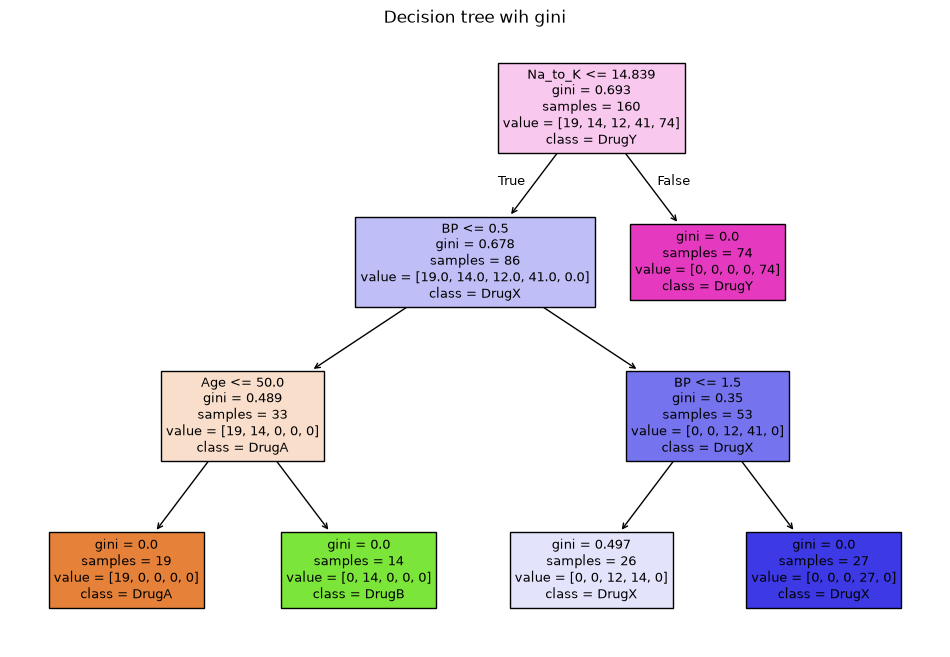

In [40]:
create_decision_tree_and_report('gini', max_depth=3, print_tree_rules=True)

#### Observaciones para este caso

- drugC: precision, recall y F1 = 0.00 con 4 muestras reales. El modelo lo confunde con otra clase 

- drugX tiene sobrepredicción: recall perfecto pero precision 0.76 indica falsos positivos; coincide con que drugC (4 casos) probablemente se clasificó como drugX.

---Matriz de confusion---
[[ 4  0  0  0  0]
 [ 0  2  0  0  0]
 [ 0  0  4  0  0]
 [ 0  0  0 13  0]
 [ 0  0  0  0 17]]
---Reporte de metricas---
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         2
       drugC       1.00      1.00      1.00         4
       drugX       1.00      1.00      1.00        13
       drugY       1.00      1.00      1.00        17

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

---Reglas del arbol---
|--- Na_to_K <= 14.84
|   |--- BP <= 0.50
|   |   |--- Age <= 50.00
|   |   |   |--- class: drugA
|   |   |--- Age >  50.00
|   |   |   |--- class: drugB
|   |--- BP >  0.50
|   |   |--- BP <= 1.50
|   |   |   |--- Cholesterol <= 1.00
|   |   |   |   |--- class: drugC
|   |   |   |--- Cholesterol >  1.00
|   |   |   |   |--- class: drugX
|   |

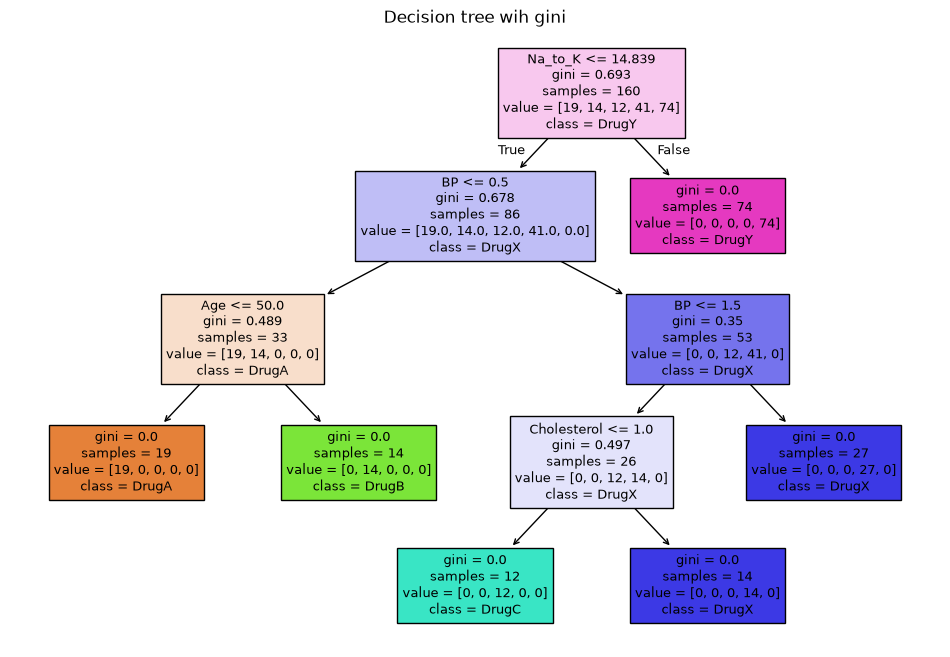

In [41]:
create_decision_tree_and_report('gini', max_depth=5, print_tree_rules= True)

[[ 4  0  0  0  0]
 [ 0  2  0  0  0]
 [ 0  0  4  0  0]
 [ 0  0  0 13  0]
 [ 0  0  0  0 17]]
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         2
       drugC       1.00      1.00      1.00         4
       drugX       1.00      1.00      1.00        13
       drugY       1.00      1.00      1.00        17

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



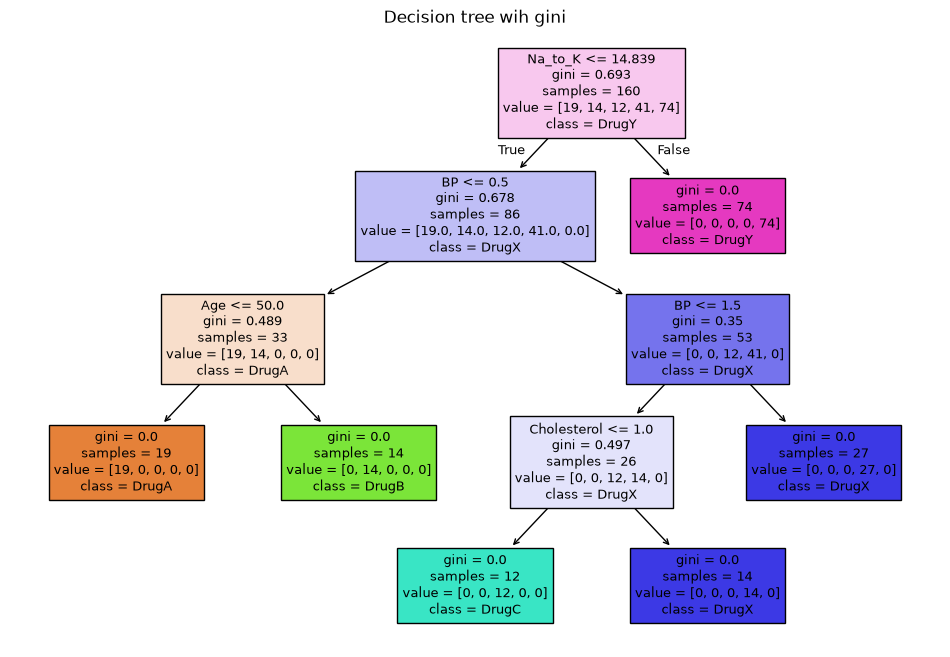

In [29]:
create_decision_tree_and_report('gini', max_depth=7)

## Entropia

[[ 4  0  0  0  0]
 [ 0  2  0  0  0]
 [ 0  0  0  4  0]
 [ 0  0  0 13  0]
 [ 0  0  0  0 17]]
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         2
       drugC       0.00      0.00      0.00         4
       drugX       0.76      1.00      0.87        13
       drugY       1.00      1.00      1.00        17

    accuracy                           0.90        40
   macro avg       0.75      0.80      0.77        40
weighted avg       0.82      0.90      0.86        40



/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

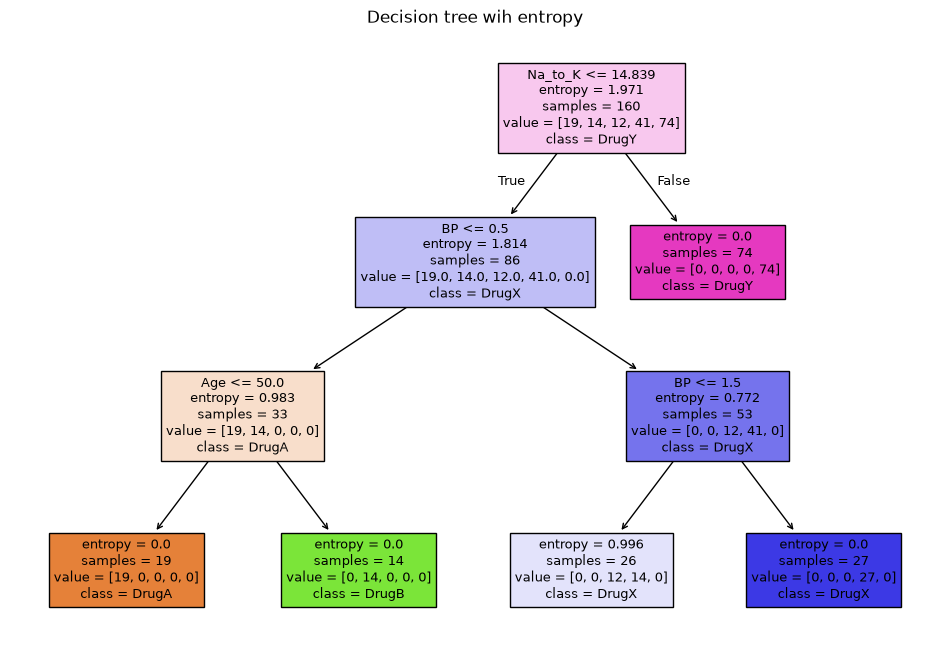

In [26]:
create_decision_tree_and_report('entropy', 3)

[[ 4  0  0  0  0]
 [ 0  2  0  0  0]
 [ 0  0  4  0  0]
 [ 0  0  0 13  0]
 [ 0  0  0  0 17]]
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         2
       drugC       1.00      1.00      1.00         4
       drugX       1.00      1.00      1.00        13
       drugY       1.00      1.00      1.00        17

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



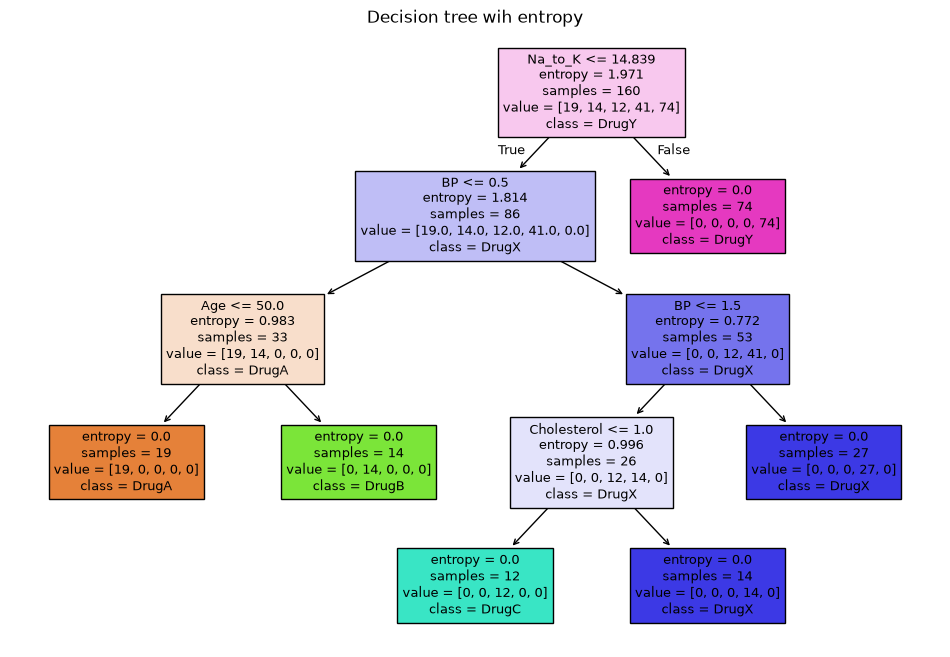

In [27]:
create_decision_tree_and_report('entropy', 5)

## Resultados

| Criterion  | Max_depth | Acuracy (F1-score)  | Comentarios  |
|---------|-----------|--------|----------|
| gini  |     3       |    0.9  |    Este modelo descarta la categoria **drugC**     |
| gini  |     5       |   1     |    El modelo considera todas las categorias       |
| gini  |     7       |    1    |    Es similar a **max_depth = 5**     |
| entropy |     3     |    0.9  |     Este modelo no considera la categoria **drugC**     |
| entropy |     5     |    1    |   Los resultados son similares a gini, **max_depth = 5 **      |


## Prediccion de medicamento 

El arbol de desicion predice que el medicamento para los datos datos dados es drugY

In [43]:
X_test_2 = [[23, 0, 0, 1, 25.355]]
# Build the desicion tree classifier model
clf = DecisionTreeClassifier(criterion='entropy', max_depth=5)

# Apply the model to the training data 
clf = clf.fit(X_train, Y_train)

# Predict the response for the test dataset
y_hat = clf.predict(X_test_2)
y_hat

tree_rules = tree.export_text(clf, feature_names=feature_columns, max_depth=5)
print('---Reglas del arbol---')
print(tree_rules)

---Reglas del arbol---
|--- Na_to_K <= 14.84
|   |--- BP <= 0.50
|   |   |--- Age <= 50.00
|   |   |   |--- class: drugA
|   |   |--- Age >  50.00
|   |   |   |--- class: drugB
|   |--- BP >  0.50
|   |   |--- BP <= 1.50
|   |   |   |--- Cholesterol <= 1.00
|   |   |   |   |--- class: drugC
|   |   |   |--- Cholesterol >  1.00
|   |   |   |   |--- class: drugX
|   |   |--- BP >  1.50
|   |   |   |--- class: drugX
|--- Na_to_K >  14.84
|   |--- class: drugY



Este ejemplo, las reglas se pueden interpetrar asi:

X = [23, F, High, Normal, 25.355]

|--- Si la proporcion de sodio/potacio es (Na_to_K) <= 14.84 entonces:

|   |--- Si la presion arterial BP <= 0.50 entonces:

|   |   |--- Si la edad Age <= 50.00 entonces:

|   |   |   |--- recomendar el medicamento class: drugA.

|   |   |--- Si la edad Age >  50.00 entonces 

|   |   |   |--- recomendar el medicamento class: drugB

|   |--- Si la presion arterial BP >  0.50 entonces

|   |   |--- Si la presion arterial BP <= 1.50

|   |   |   |--- Si el colesterol Cholesterol <= 1.00 entonces:

|   |   |   |   |--- recomendar el medicamento class: drugC

|   |   |   |--- Si el colesterol Cholesterol Cholesterol >  1.00

|   |   |   |   |--- recomendar el medicamento class: drugX

|   |   |--- Si la presion arterial BP >  1.50

|   |   |   |--- recomendar el medicamento class: drugX

|--- Si la proporcion de sodio/potacio es Na_to_K >  14.84

|   |--- recomendar el medicamento class: drugY